In [34]:
!pip install seaborn

In [35]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns




In [36]:
import pandas as pd

# The '..' tells Python to go up one level from the 'notebooks' folder
file_path = '../data/raw/ai4i_2020_predictive_maintenance.csv'

df = pd.read_csv(file_path)
print("File loaded successfully!")

File loaded successfully!


In [37]:
df.dtypes

UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

In [38]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [40]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


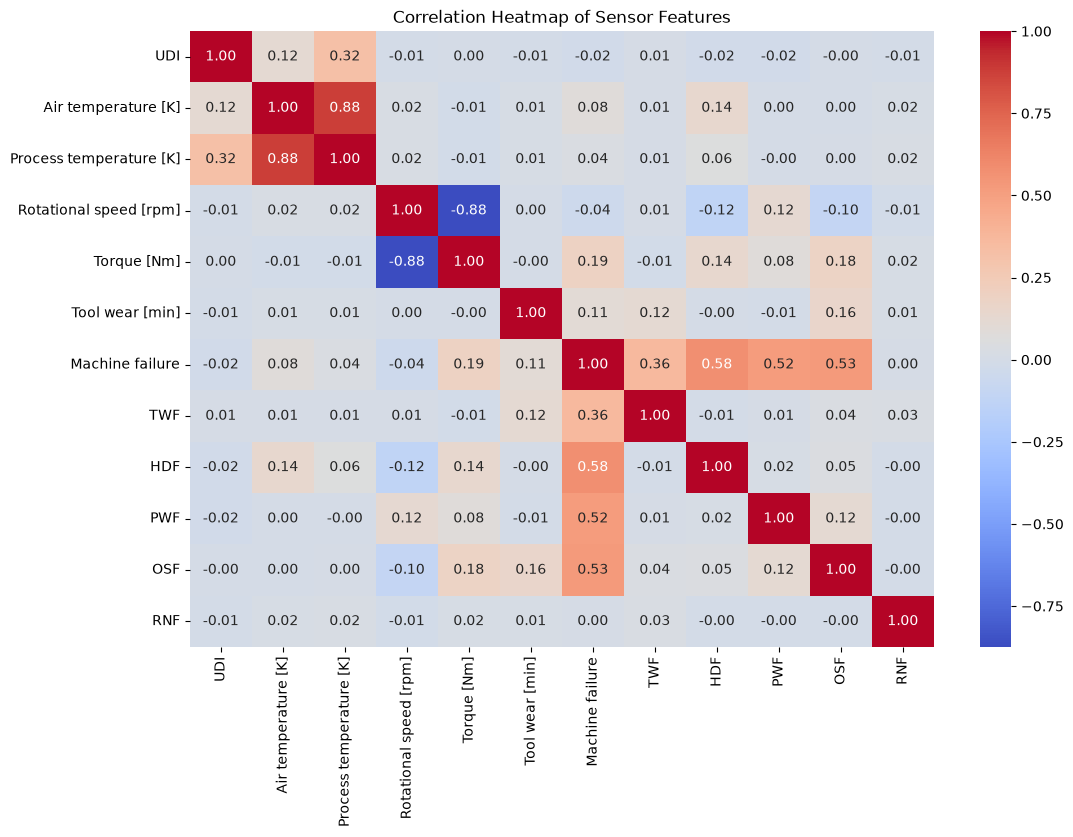

In [41]:
# Calculate correlation matrix (using only numeric columns)
correlation_matrix = df.corr(numeric_only=True)

# Generate the heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap of Sensor Features")
plt.show()

Dataset distribution:
 Machine failure
0    9661
1     339
Name: count, dtype: int64


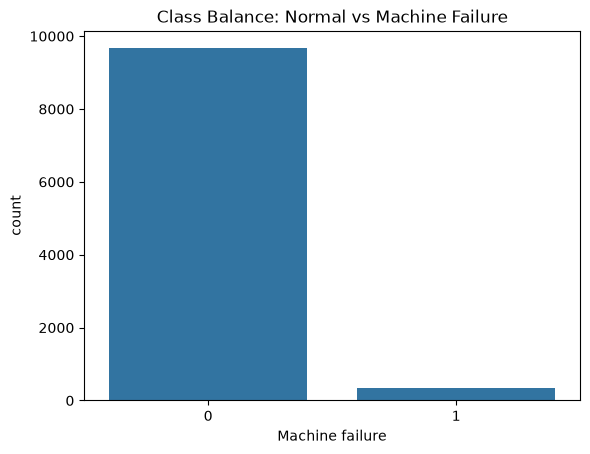

In [42]:
# Check exact counts of Failures (1) vs Normal (0)
failure_counts = df['Machine failure'].value_counts()
print("Dataset distribution:\n", failure_counts)

# Visualize the imbalance
sns.countplot(x='Machine failure', data=df)
plt.title("Class Balance: Normal vs Machine Failure")
plt.show()

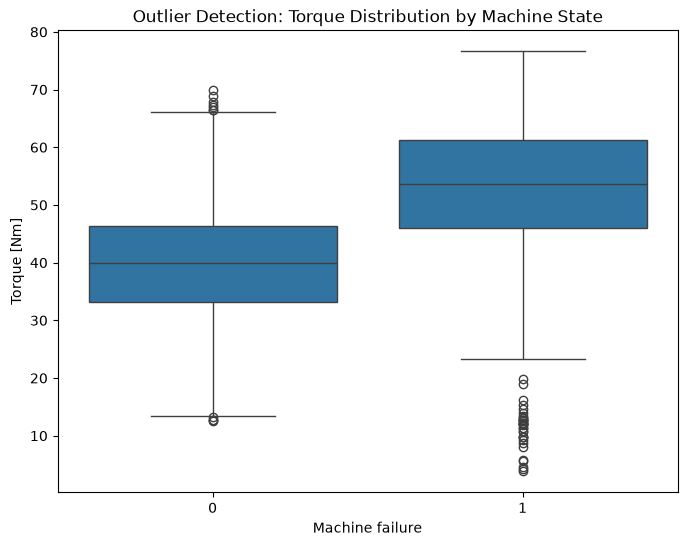

In [33]:
# Create a box plot to compare a feature (e.g., Torque) against the target (Machine failure)
plt.figure(figsize=(8, 6))
sns.boxplot(x='Machine failure', y='Torque [Nm]', data=df)
plt.title("Outlier Detection: Torque Distribution by Machine State")
plt.show()

# You can repeat this for other features:
# sns.boxplot(x='Machine failure', y='Rotational speed [rpm]', data=df)
# sns.boxplot(x='Machine failure', y='Process temperature [K]', data=df)

In [43]:
# View basic statistics (Mean, Std, Min, Max) for all features
print(df.describe())

# Check unique counts for categorical features (like Type)
print(df['Type'].value_counts())

               UDI  Air temperature [K]  Process temperature [K]  \
count  10000.00000         10000.000000             10000.000000   
mean    5000.50000           300.004930               310.005560   
std     2886.89568             2.000259                 1.483734   
min        1.00000           295.300000               305.700000   
25%     2500.75000           298.300000               308.800000   
50%     5000.50000           300.100000               310.100000   
75%     7500.25000           301.500000               311.100000   
max    10000.00000           304.500000               313.800000   

       Rotational speed [rpm]   Torque [Nm]  Tool wear [min]  Machine failure  \
count            10000.000000  10000.000000     10000.000000     10000.000000   
mean              1538.776100     39.986910       107.951000         0.033900   
std                179.284096      9.968934        63.654147         0.180981   
min               1168.000000      3.800000         0.000000   

In [44]:
# Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

# Remove duplicates if found
df = df.drop_duplicates()

Number of duplicate rows: 0


In [45]:
# Check for impossible physical values
# For example, temperature in Kelvin should never be 0 or negative
invalid_temp = df[df['Air temperature [K]'] <= 0]
print(f"Invalid temperature readings: {len(invalid_temp)}")

# Check if any Rotational speed or Torque values are negative where they shouldn't be
print(df[df['Rotational speed [rpm]'] < 0])
print(df[df['Torque [Nm]'] < 0])

Invalid temperature readings: 0
Empty DataFrame
Columns: [UDI, Product ID, Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Machine failure, TWF, HDF, PWF, OSF, RNF]
Index: []
Empty DataFrame
Columns: [UDI, Product ID, Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min], Machine failure, TWF, HDF, PWF, OSF, RNF]
Index: []


In [46]:
# Function to detect outliers using IQR
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] < lower_bound) | (df[column] > upper_bound)]

# Check for outliers in Torque
torque_outliers = detect_outliers(df, 'Torque [Nm]')
print(f"Number of outliers in Torque: {len(torque_outliers)}")

Number of outliers in Torque: 69


In [47]:
# Check unique values in the 'Type' column to ensure no typos exist
print(df['Type'].unique())

# Ensure the 'Machine failure' column only contains 0 and 1
print(df['Machine failure'].unique())

<StringArray>
['M', 'L', 'H']
Length: 3, dtype: str
[0 1]


In [48]:
import os

# Create the directory if it doesn't exist
os.makedirs('../data/processed', exist_ok=True)

# Save the clean dataframe to a CSV file
df.to_csv('../data/processed/cleaned_data.csv', index=False)

print("Dataset successfully saved to data/processed/cleaned_data.csv")

Dataset successfully saved to data/processed/cleaned_data.csv
